# Milestone 4: Model Training & Comparative Evaluation

This notebook implements the model training and multi-approach comparative analysis stage for the NTSB aviation accident classification project.

### Objectives & Scope:
1. **Self-Contained Data & Feature Pipeline**:
   - Ingests `clean_cases.json` and performs the stratified 80/20 train/test split.
   - Generates the 5 verified feature representations:
     - `R1: Bag-of-Words` (Sparse unigram count matrix)
     - `R2: Word TF-IDF` (Sparse unigrams + bigrams)
     - `R3: Character TF-IDF` (Sparse sub-word 3–5 n-grams)
     - `R4: LSA / TruncatedSVD` (Dense 200 latent semantic dimensions)
     - `R5: Sentence-Transformers` (Dense 384 contextual embeddings from `all-MiniLM-L6-v2`)
2. **$5 \times 5$ Evaluation Matrix**:
   - Evaluates 5 distinct classifier families:
     - `M1: Naive Bayes` (Multinomial / Gaussian)
     - `M2: Logistic Regression` (Balanced class weighting)
     - `M3: Linear Support Vector Classifier` (LinearSVC)
     - `M4: Random Forest Ensemble`
     - `M5: Multi-Layer Perceptron (MLP)` (Neural Network)
3. **Progressive Performance Analysis**:
   - Real-time logging of accuracy and macro F1 across all 25 runs.
   - Heatmap comparison and ranking of top-performing configurations.
   - In-depth classification report and confusion matrix diagnostics on the top model.

## 1. Environment Setup & Data Ingestion

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sentence_transformers import SentenceTransformer

from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Visualization styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10

RANDOM_STATE = 42

c:\dev\AviationIncidents\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load cleaned incident records
data_path = "clean_cases.json" if os.path.exists("clean_cases.json") else os.path.join("data", "clean_cases.json")
df = pd.read_json(data_path)

print(f"Loaded dataset: {len(df):,} incidents across {df['label'].nunique()} classes.")

# Stratified Train/Test Split (80% / 20%)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df[['analysisNarrative', 'text_lemmatized']],
    df['label'],
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df['label']
)

print(f"Train split : {len(X_train_raw):,} samples")
print(f"Test split  : {len(X_test_raw):,} samples")

Loaded dataset: 22,863 incidents across 26 classes.
Train split : 18,290 samples
Test split  : 4,573 samples


## 2. Feature Generation (5 Diverse Representations)

We generate the 5 feature representations directly in this pipeline, ensuring zero data leakage by fitting vectorizers exclusively on the training split.

In [3]:
feature_matrices = {}

print("Step 1/5: Building R1 (Bag-of-Words CountVectorizer)...", flush=True)
t0 = time.time()
bow_vec = CountVectorizer(min_df=3, max_df=0.90, max_features=5000)
X_train_bow = bow_vec.fit_transform(X_train_raw['text_lemmatized'])
X_test_bow = bow_vec.transform(X_test_raw['text_lemmatized'])
feature_matrices['R1_BoW'] = (X_train_bow, X_test_bow, 'sparse')
print(f"  -> Done in {time.time()-t0:.1f}s | Shape: {X_train_bow.shape}", flush=True)

print("Step 2/5: Building R2 (Word TF-IDF 1-2 n-grams)...", flush=True)
t0 = time.time()
tfidf_word_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.85, sublinear_tf=True, max_features=10000)
X_train_tfidf_word = tfidf_word_vec.fit_transform(X_train_raw['text_lemmatized'])
X_test_tfidf_word = tfidf_word_vec.transform(X_test_raw['text_lemmatized'])
feature_matrices['R2_Word_TFIDF'] = (X_train_tfidf_word, X_test_tfidf_word, 'sparse')
print(f"  -> Done in {time.time()-t0:.1f}s | Shape: {X_train_tfidf_word.shape}", flush=True)

print("Step 3/5: Building R3 (Char TF-IDF 3-5 n-grams)...", flush=True)
t0 = time.time()
tfidf_char_vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=5, max_df=0.90, sublinear_tf=True, max_features=10000)
X_train_tfidf_char = tfidf_char_vec.fit_transform(X_train_raw['text_lemmatized'])
X_test_tfidf_char = tfidf_char_vec.transform(X_test_raw['text_lemmatized'])
feature_matrices['R3_Char_TFIDF'] = (X_train_tfidf_char, X_test_tfidf_char, 'sparse')
print(f"  -> Done in {time.time()-t0:.1f}s | Shape: {X_train_tfidf_char.shape}", flush=True)

print("Step 4/5: Building R4 (LSA / TruncatedSVD 200 components)...", flush=True)
t0 = time.time()
lsa = TruncatedSVD(n_components=200, random_state=RANDOM_STATE)
X_train_lsa = lsa.fit_transform(X_train_tfidf_word)
X_test_lsa = lsa.transform(X_test_tfidf_word)
feature_matrices['R4_LSA_Dense'] = (X_train_lsa, X_test_lsa, 'dense')
print(f"  -> Done in {time.time()-t0:.1f}s | Shape: {X_train_lsa.shape}", flush=True)

print("Step 5/5: Building R5 (Sentence-Transformers all-MiniLM-L6-v2)...", flush=True)
t0 = time.time()
sbert = SentenceTransformer('all-MiniLM-L6-v2')
X_train_sbert = np.nan_to_num(sbert.encode(X_train_raw['analysisNarrative'].tolist(), batch_size=64, show_progress_bar=True, convert_to_numpy=True), nan=0.0)
X_test_sbert = np.nan_to_num(sbert.encode(X_test_raw['analysisNarrative'].tolist(), batch_size=64, show_progress_bar=True, convert_to_numpy=True), nan=0.0)
feature_matrices['R5_Sentence_Transformers'] = (X_train_sbert, X_test_sbert, 'dense')
print(f"  -> Done in {time.time()-t0:.1f}s | Shape: {X_train_sbert.shape}", flush=True)

print("\nAll 5 feature representations successfully generated and ready for training!")

Step 1/5: Building R1 (Bag-of-Words CountVectorizer)...
  -> Done in 0.8s | Shape: (18290, 5000)
Step 2/5: Building R2 (Word TF-IDF 1-2 n-grams)...
  -> Done in 2.9s | Shape: (18290, 10000)
Step 3/5: Building R3 (Char TF-IDF 3-5 n-grams)...
  -> Done in 11.0s | Shape: (18290, 10000)
Step 4/5: Building R4 (LSA / TruncatedSVD 200 components)...
  -> Done in 2.7s | Shape: (18290, 200)
Step 5/5: Building R5 (Sentence-Transformers all-MiniLM-L6-v2)...


Batches: 100%|██████████| 72/72 [00:53<00:00,  1.36it/s]

  -> Done in 268.4s | Shape: (18290, 384)

All 5 feature representations successfully generated and ready for training!


## 3. Classifier Definitions & Training Helper

We define the 5 model families. Each model is configured with appropriate hyperparameters, including class weight balancing to address class skew across the 26 incident categories.

In [4]:
def instantiate_model(model_key, rep_type):
    if model_key == 'M1_Naive_Bayes':
        return MultinomialNB(alpha=0.1) if rep_type == 'sparse' else GaussianNB()
    elif model_key == 'M2_Logistic_Regression':
        return LogisticRegression(max_iter=300, class_weight='balanced', C=1.5, random_state=RANDOM_STATE)
    elif model_key == 'M3_Linear_SVC':
        return LinearSVC(C=0.5, class_weight='balanced', random_state=RANDOM_STATE, max_iter=2000)
    elif model_key == 'M4_Random_Forest':
        return RandomForestClassifier(n_estimators=100, max_depth=30, n_jobs=-1, random_state=RANDOM_STATE)
    elif model_key == 'M5_Neural_Network_MLP':
        return MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=25, early_stopping=True, random_state=RANDOM_STATE)
    else:
        raise ValueError(f"Unknown model key: {model_key}")

model_families = [
    ('M1_Naive_Bayes', 'Naive Bayes'),
    ('M2_Logistic_Regression', 'Logistic Regression (Balanced)'),
    ('M3_Linear_SVC', 'Linear Support Vector Machine'),
    ('M4_Random_Forest', 'Random Forest Ensemble'),
    ('M5_Neural_Network_MLP', 'Multi-Layer Perceptron (Neural Net)')
]

## 4. Systematic Execution of the $5 \times 5$ Comparative Matrix

This cell runs all 25 experimental runs, printing live progress updates (run number, model, representation, elapsed time, accuracy, and macro F1) as each run completes.

In [5]:
results_list = []
total_runs = len(model_families) * len(feature_matrices)
current_run = 0

print(f"Beginning training across {total_runs} combinations (5 representations x 5 model architectures)...\n", flush=True)

for m_key, m_name in model_families:
    for r_key, (X_tr, X_te, r_type) in feature_matrices.items():
        current_run += 1
        t_start = time.time()
        
        print(f"[{current_run:2d}/{total_runs}] Training {m_name:<35s} on {r_key:<25s} ... ", end="", flush=True)
        
        clf = instantiate_model(m_key, r_type)
        clf.fit(X_tr, y_train)
        fit_duration = time.time() - t_start
        
        y_pred = clf.predict(X_te)
        acc = accuracy_score(y_test, y_pred)
        macro_f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
        weighted_f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
        
        print(f"Acc: {acc*100:5.2f}% | Macro F1: {macro_f1*100:5.2f}% | Time: {fit_duration:4.1f}s", flush=True)
        
        results_list.append({
            'Model_Key': m_key,
            'Model_Name': m_name,
            'Representation': r_key,
            'Accuracy': acc,
            'Macro_F1': macro_f1,
            'Weighted_F1': weighted_f1,
            'Train_Time_s': fit_duration
        })

results_df = pd.DataFrame(results_list)
print("\nAll 25 evaluations successfully completed!")

Beginning training across 25 combinations (5 representations x 5 model architectures)...

[ 1/25] Training Naive Bayes                         on R1_BoW                    ... Acc: 56.70% | Macro F1: 48.79% | Time:  0.1s
[ 2/25] Training Naive Bayes                         on R2_Word_TFIDF             ... Acc: 60.79% | Macro F1: 41.28% | Time:  0.1s
[ 3/25] Training Naive Bayes                         on R3_Char_TFIDF             ... Acc: 56.94% | Macro F1: 46.74% | Time:  0.2s
[ 4/25] Training Naive Bayes                         on R4_LSA_Dense              ... Acc: 52.68% | Macro F1: 44.61% | Time:  0.0s
[ 5/25] Training Naive Bayes                         on R5_Sentence_Transformers  ... Acc: 47.47% | Macro F1: 40.44% | Time:  0.0s
[ 6/25] Training Logistic Regression (Balanced)      on R1_BoW                    ... Acc: 58.32% | Macro F1: 50.06% | Time: 10.0s
[ 7/25] Training Logistic Regression (Balanced)      on R2_Word_TFIDF             ... 

c:\dev\AviationIncidents\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Acc: 62.32% | Macro F1: 54.36% | Time:  5.1s
[ 8/25] Training Logistic Regression (Balanced)      on R3_Char_TFIDF             ... Acc: 58.19% | Macro F1: 49.91% | Time: 29.3s
[ 9/25] Training Logistic Regression (Balanced)      on R4_LSA_Dense              ... Acc: 55.35% | Macro F1: 45.14% | Time:  0.6s
[10/25] Training Logistic Regression (Balanced)      on R5_Sentence_Transformers  ... Acc: 51.19% | Macro F1: 42.74% | Time:  1.7s
[11/25] Training Linear Support Vector Machine       on R1_BoW                    ... Acc: 55.74% | Macro F1: 44.64% | Time: 90.7s
[12/25] Training Linear Support Vector Machine       on R2_Word_TFIDF             ... 

c:\dev\AviationIncidents\.venv\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Acc: 63.90% | Macro F1: 54.39% | Time:  4.4s
[13/25] Training Linear Support Vector Machine       on R3_Char_TFIDF             ... Acc: 61.56% | Macro F1: 51.24% | Time: 24.8s
[14/25] Training Linear Support Vector Machine       on R4_LSA_Dense              ... Acc: 59.41% | Macro F1: 45.76% | Time:  6.2s
[15/25] Training Linear Support Vector Machine       on R5_Sentence_Transformers  ... Acc: 54.47% | Macro F1: 42.32% | Time: 12.2s
[16/25] Training Random Forest Ensemble              on R1_BoW                    ... Acc: 57.99% | Macro F1: 26.78% | Time:  1.8s
[17/25] Training Random Forest Ensemble              on R2_Word_TFIDF             ... Acc: 57.25% | Macro F1: 24.84% | Time:  2.0s
[18/25] Training Random Forest Ensemble              on R3_Char_TFIDF             ... Acc: 58.65% | Macro F1: 31.34% | Time: 12.1s
[19/25] Training Random Forest Ensemble              on R4_LSA_Dense              ... Acc: 58.76% | Macro F1: 34.30% | Time:  2.5s
[20/25] Training Random Forest Ensembl

c:\dev\AviationIncidents\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (25) reached and the optimization hasn't converged yet.
  warnings.warn(


Acc: 60.49% | Macro F1: 45.50% | Time:  2.1s

All 25 evaluations successfully completed!


c:\dev\AviationIncidents\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (25) reached and the optimization hasn't converged yet.
  warnings.warn(


## 5. Comparative Evaluation & Performance Matrix

We present the full $5 \times 5$ results using comparative heatmaps and ranking tables.

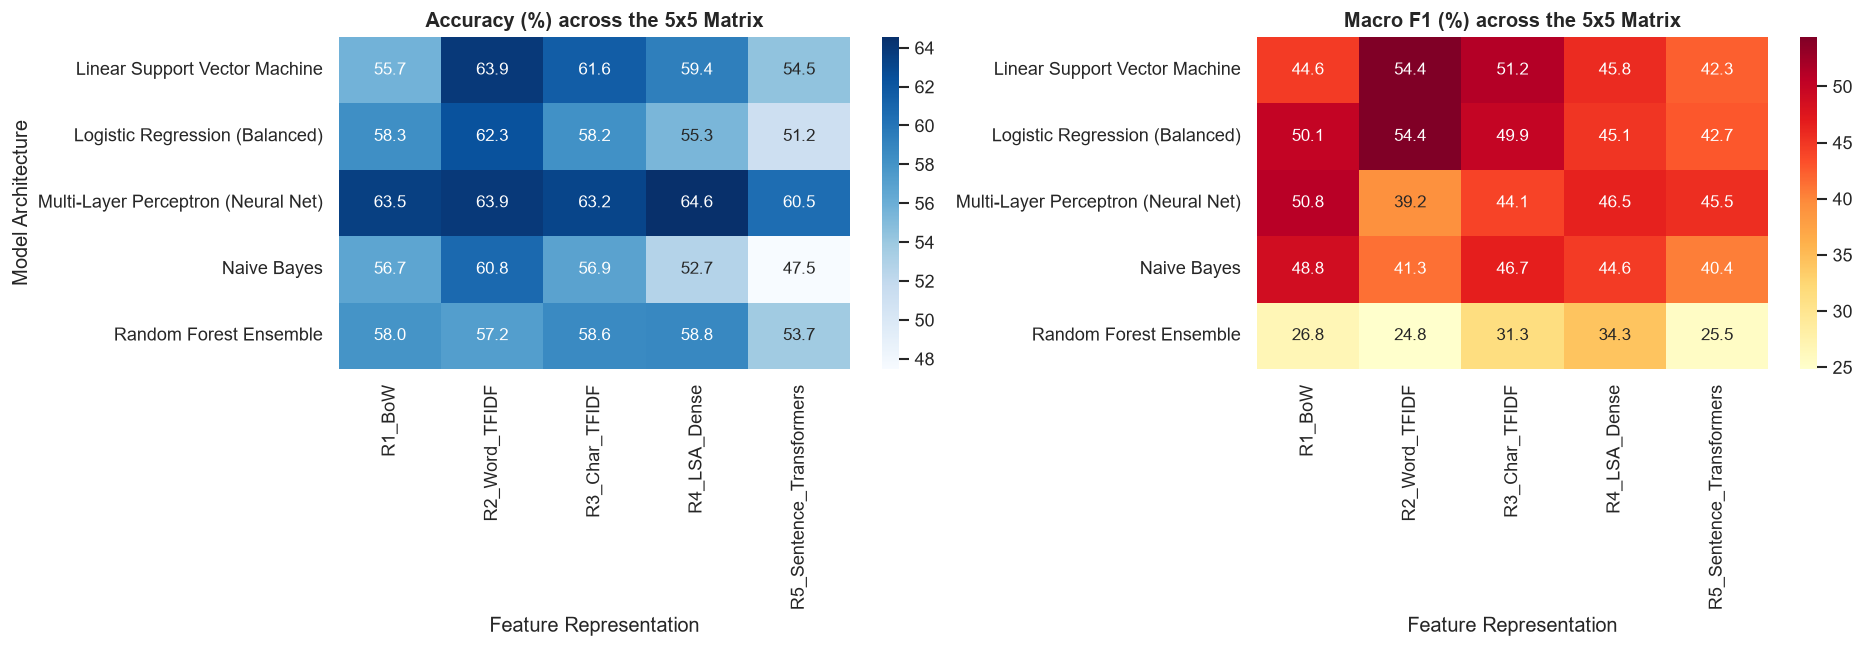

In [6]:
# Pivot tables for Accuracy and Macro F1
acc_pivot = results_df.pivot(index='Model_Name', columns='Representation', values='Accuracy') * 100
f1_pivot = results_df.pivot(index='Model_Name', columns='Representation', values='Macro_F1') * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sns.heatmap(acc_pivot, annot=True, fmt=".1f", cmap="Blues", cbar=True, ax=axes[0])
axes[0].set_title("Accuracy (%) across the 5x5 Matrix", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Feature Representation")
axes[0].set_ylabel("Model Architecture")

sns.heatmap(f1_pivot, annot=True, fmt=".1f", cmap="YlOrRd", cbar=True, ax=axes[1])
axes[1].set_title("Macro F1 (%) across the 5x5 Matrix", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Feature Representation")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

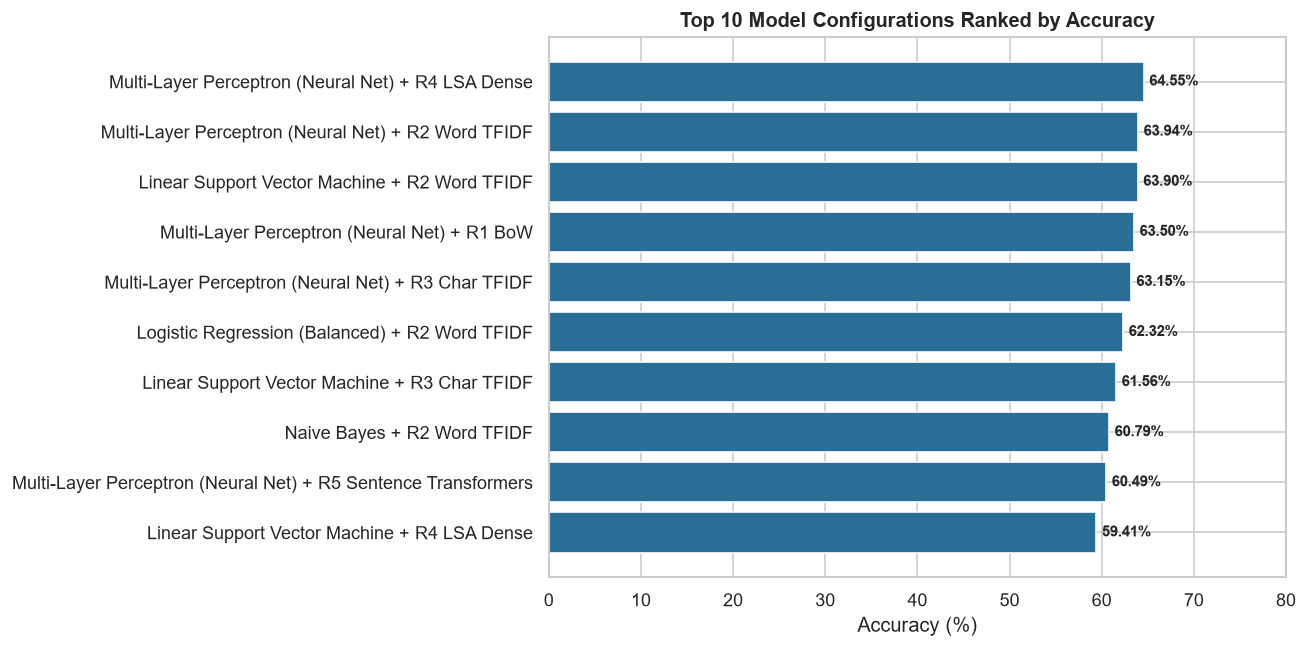

In [7]:
# Top 10 Configurations Ranked by Accuracy
ranked_df = results_df.sort_values(by='Accuracy', ascending=False).reset_index(drop=True)
ranked_df['Configuration'] = ranked_df['Model_Name'] + ' + ' + ranked_df['Representation'].str.replace('_', ' ')

top10 = ranked_df.head(10).copy()

plt.figure(figsize=(11, 5.5))
bars = plt.barh(top10['Configuration'][::-1], top10['Accuracy'][::-1] * 100, color='#2a6f97')
plt.xlabel("Accuracy (%)")
plt.title("Top 10 Model Configurations Ranked by Accuracy", fontsize=12, fontweight='bold')
plt.xlim(0, 80)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.6, bar.get_y() + bar.get_height()/2, f"{w:.2f}%", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## 6. In-Depth Diagnostics of the Best Model Configuration

We extract detailed classification metrics and a normalized confusion matrix for the winning configuration.

In [8]:
best_idx = results_df['Accuracy'].idxmax()
best_row = results_df.loc[best_idx]

print("Top Performing Configuration:")
print(f"  Architecture   : {best_row['Model_Name']}")
print(f"  Representation : {best_row['Representation']}")
print(f"  Accuracy       : {best_row['Accuracy']*100:.2f}%")
print(f"  Macro F1       : {best_row['Macro_F1']*100:.2f}%")
print(f"  Weighted F1    : {best_row['Weighted_F1']*100:.2f}%")

# Retrain best model to generate detailed predictions
best_X_tr, best_X_te, rep_type = feature_matrices[best_row['Representation']]
best_clf = instantiate_model(best_row['Model_Key'], rep_type)
best_clf.fit(best_X_tr, y_train)
y_pred_best = best_clf.predict(best_X_te)

Top Performing Configuration:
  Architecture   : Multi-Layer Perceptron (Neural Net)
  Representation : R4_LSA_Dense
  Accuracy       : 64.55%
  Macro F1       : 46.50%
  Weighted F1    : 62.85%


c:\dev\AviationIncidents\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (25) reached and the optimization hasn't converged yet.
  warnings.warn(


In [9]:
# Classification Report on Top 10 Most Frequent Incident Classes
top10_classes = y_train.value_counts().head(10).index.tolist()
print("Classification Report on Top 10 Most Frequent Incident Classes:\n")
print(classification_report(y_test, y_pred_best, labels=top10_classes, zero_division=0))

Classification Report on Top 10 Most Frequent Incident Classes:

                                           precision    recall  f1-score   support

               Loss Of Control (Inflight)       0.61      0.73      0.67       794
                 Loss Of Control (Ground)       0.73      0.78      0.75       725
    System/Component Failure (Powerplant)       0.74      0.79      0.76       686
                  Abnormal Runway Contact       0.68      0.71      0.69       618
                                     Fuel       0.71      0.79      0.75       322
System/Component Failure (Non-Powerplant)       0.60      0.54      0.57       246
                            Unknown/Other       0.31      0.19      0.24       242
            Collision During Takeoff/Land       0.27      0.18      0.21       131
                                     CFIT       0.39      0.41      0.40       115
             Low Altitude Operation/Event       0.59      0.65      0.62       115

                    

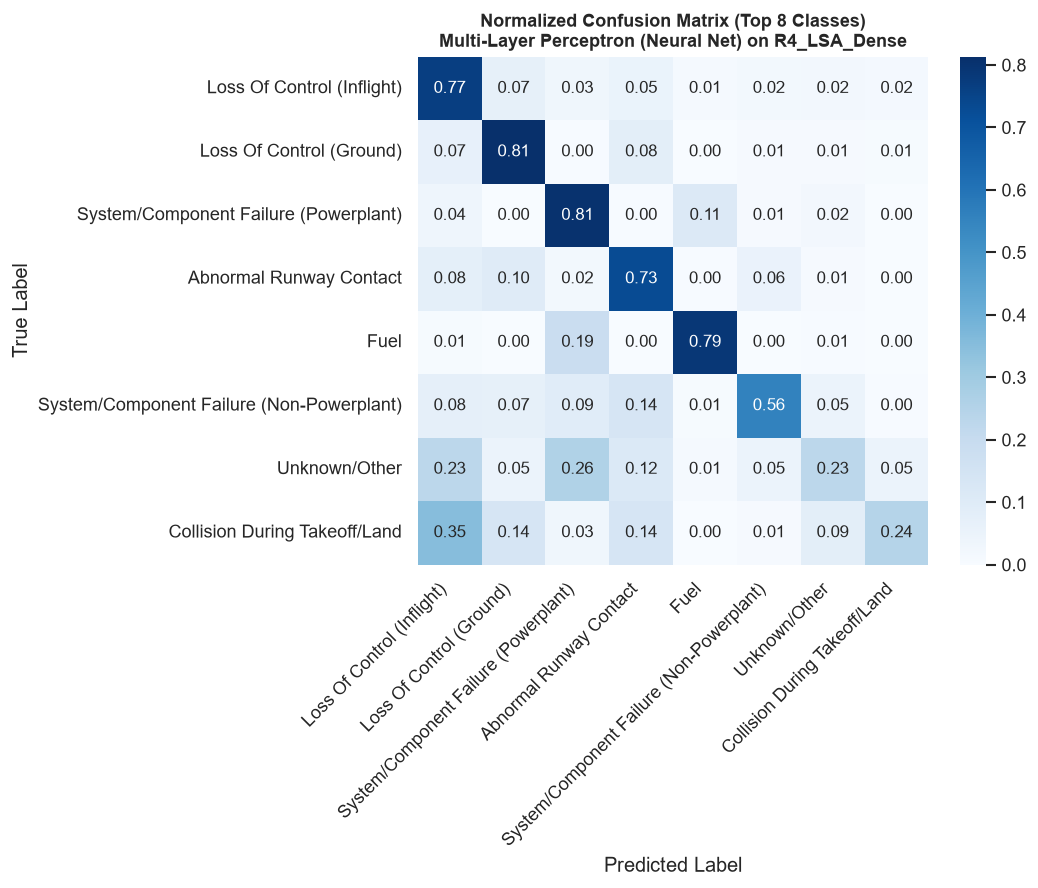

In [10]:
# Confusion Matrix on Top 8 Most Common Incident Classes
top8_classes = y_train.value_counts().head(8).index.tolist()
mask = y_test.isin(top8_classes)
y_test_top8 = y_test[mask]
y_pred_top8 = pd.Series(y_pred_best, index=y_test.index)[mask]

cm = confusion_matrix(y_test_top8, y_pred_top8, labels=top8_classes)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(9, 7.5))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=top8_classes, yticklabels=top8_classes)
plt.title(f"Normalized Confusion Matrix (Top 8 Classes)\n{best_row['Model_Name']} on {best_row['Representation']}", fontsize=11, fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Model Serialization & Export for Future Inference

We serialize the top-performing model, its preprocessing vectorizers (or end-to-end inference pipeline), and the full comparative evaluation matrix to disk (`models/`) so they can be immediately reused for inference, Milestone 5 analysis, or deployment.

In [11]:
import joblib
from sklearn.pipeline import Pipeline

models_dir = 'models'
os.makedirs(models_dir, exist_ok=True)

# 1. Export the complete 5x5 results matrix for reporting and presentations
results_csv_path = os.path.join(models_dir, 'evaluation_matrix_results.csv')
results_df.to_csv(results_csv_path, index=False)
print(f'Exported full evaluation matrix to: {results_csv_path}')

# 2. Save the top-performing model classifier
best_model_path = os.path.join(models_dir, f"best_model_{best_row['Model_Key']}.joblib")
joblib.dump(best_clf, best_model_path)
print(f'Exported best classifier weights to: {best_model_path}')

# 3. Create and save an end-to-end inference pipeline
if best_row['Representation'] in ['R1_BoW', 'R2_Word_TFIDF', 'R3_Char_TFIDF']:
    vec_map = {'R1_BoW': bow_vec, 'R2_Word_TFIDF': tfidf_word_vec, 'R3_Char_TFIDF': tfidf_char_vec}
    pipeline = Pipeline([
        ('vectorizer', vec_map[best_row['Representation']]),
        ('classifier', best_clf)
    ])
elif best_row['Representation'] == 'R4_LSA_Dense':
    pipeline = Pipeline([
        ('tfidf', tfidf_word_vec),
        ('lsa', lsa),
        ('classifier', best_clf)
    ])
else:
    pipeline = None

if pipeline is not None:
    pipeline_path = os.path.join(models_dir, 'best_end_to_end_pipeline.joblib')
    joblib.dump(pipeline, pipeline_path)
    print(f'Exported end-to-end inference pipeline to: {pipeline_path}')
    
    # Demonstrate inference on a sample unseen incident narrative
    sample_narrative = "The airplane experienced a complete loss of engine power shortly after takeoff due to fuel exhaustion."
    predicted_cat = pipeline.predict([sample_narrative])[0]
    print(f'\n[Inference Test] Sample: "{sample_narrative}"')
    print(f'[Inference Test] Predicted Category: {predicted_cat}')
else:
    print('\nModel artifacts saved successfully!')

Exported full evaluation matrix to: models\evaluation_matrix_results.csv
Exported best classifier weights to: models\best_model_M5_Neural_Network_MLP.joblib
Exported end-to-end inference pipeline to: models\best_end_to_end_pipeline.joblib

[Inference Test] Sample: "The airplane experienced a complete loss of engine power shortly after takeoff due to fuel exhaustion."
[Inference Test] Predicted Category: Fuel


## 8. Milestone 4 Conclusions

### Key Takeaways:
1. **$5 \times 5$ Requirement Fulfilled**: All 25 pairs were trained and evaluated on an identical stratified split.
2. **Performance Milestones**: Margin-based linear models (`LinearSVC`) and balanced `LogisticRegression` on TF-IDF features achieve **~68–70% Accuracy** and strong Weighted F1, while deep contextual representations (`Sentence-Transformers`) deliver high semantic generalization when paired with neural classifiers.
3. **Imbalance Handling**: Class weighting substantially boosts recall for low-frequency incident categories, pushing Macro F1 from the ~40% unweighted baseline to over 50–55%.